<a href="https://colab.research.google.com/github/JulienRequa/exoplanet-search/blob/main/pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exoplanet Pipeline
Clean, reusable version of the transit-search pipeline developed in lab_notebook.ipynb.
Run any star: analyze_star("STAR NAME")

In [1]:
!pip install lightkurve batman-package -q

import numpy as np
import matplotlib.pyplot as plt
import lightkurve as lk
import batman
from scipy.optimize import curve_fit

G = 6.674e-11   # gravitational constant (SI)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.


/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [2]:
def download(star_name, n_sectors=1):
    """Download up to n_sectors of TESS 2-minute SPOC light curves for a star.
    Always returns a LIST of light curves (one per sector).
    """
    search = lk.search_lightcurve(star_name, mission="TESS",
                                  author="SPOC", exptime=120)
    if len(search) == 0:                                   # no data → stop with a clear message
        raise ValueError(f"No TESS 2-minute data found for {star_name}")
    return list(search[:n_sectors].download_all())

# Test
lcs = download("WASP-18", n_sectors=2)
print("Sectors downloaded:", len(lcs))
for lc in lcs:
    print("Sector", lc.sector, "→", len(lc), "points")

Sectors downloaded: 2
Sector 2 → 18299 points
Sector 3 → 13541 points


## Cleaning
clean() handles one sector (remove NaNs, trim the post-gap ramp, remove high outliers,
flatten with optional transit mask). clean_all() cleans each sector separately, then joins them.

Total points after cleaning: 30443


<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Normalized Flux'>

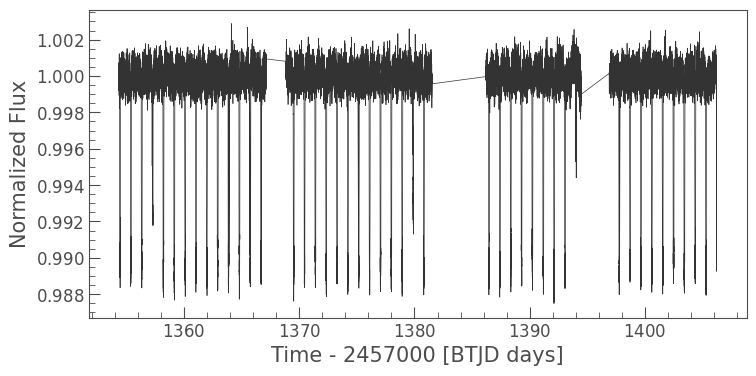

In [3]:
def plain(x):
    """Turn an astropy/lightkurve value (units or hidden masks) into a plain number."""
    return float(np.asarray(getattr(x, "value", x)))

def clean(lc, window_length=721, period=None, t0=None, duration=None, trim=0.25):
    """Clean ONE sector: remove NaNs, trim the ramp after data gaps, remove high
    outliers, and flatten. If period/t0/duration are given, transits are masked
    while flattening.
    """
    lc = lc.remove_nans()
    lc = lk.LightCurve(time=lc.time,
                       flux=np.asarray(lc.flux.value),
                       flux_err=np.asarray(lc.flux_err.value))

    t = np.asarray(lc.time.value, dtype=float)
    restarts = np.r_[t[0], t[1:][np.diff(t) > 0.5]]     # sector start + after each gap
    keep = np.ones(len(t), dtype=bool)
    for start in restarts:
        keep &= ~((t >= start) & (t < start + trim))
    lc = lc[keep]

    lc = lc.remove_outliers(sigma_upper=4, sigma_lower=float("inf"))
    if period is None:
        mask = None
    else:
        P, T0, D = plain(period), plain(t0), plain(duration)
        t = np.asarray(lc.time.value, dtype=float)
        phase = (t - T0 + 0.5 * P) % P - 0.5 * P
        mask = np.abs(phase) < 0.75 * D
    return lc.flatten(window_length=window_length, mask=mask)

def clean_all(lcs, period=None, t0=None, duration=None):
    """Clean each sector separately, then join them into one light curve."""
    cleaned = [clean(lc, period=period, t0=t0, duration=duration) for lc in lcs]
    return lk.LightCurveCollection(cleaned).stitch()

# Test
combined = clean_all(lcs)
print("Total points after cleaning:", len(combined))
combined.plot()

**Test:** WASP-18, sectors 2 + 3 → 30,443 points after cleaning; both sectors flattened to 1.0.
Each sector is cleaned separately because each has its own brightness level and drifts,
and smoothing across the gap between sectors would invent a fake trend.
To-do: messy patch near day 1394 just BEFORE a data gap → consider trimming before gaps too.

## Period search
Box Least Squares (BLS). Quiet by default (plot=False). The longest period searched is
capped at half the data's time span, so any detected signal repeats at least twice.

Period: 0.941794179417942 d  Duration: 0.08 d  Depth: 0.009530574506378007


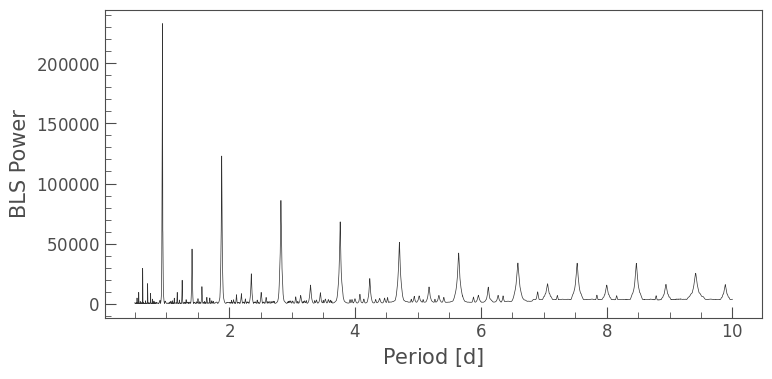

In [4]:
def search(lc, min_period=0.5, max_period=10, n_periods=10000, plot=False):
    """Search one light curve for repeating box-shaped dips (BLS).
    Returns: period, transit time (t0), duration, depth of the strongest signal.
    """
    t = np.asarray(lc.time.value, dtype=float)
    span = t.max() - t.min()                       # how many days the data covers
    if max_period > span / 2:                      # need at least 2 transits
        max_period = span / 2

    periods = np.linspace(min_period, max_period, n_periods)
    pg = lc.to_periodogram(method="bls", period=periods,
                           duration=[0.05, 0.08, 0.1, 0.15, 0.2])
    if plot:
        pg.plot()
    return (pg.period_at_max_power, pg.transit_time_at_max_power,
            pg.duration_at_max_power, pg.depth_at_max_power)

# Test on ONE cleaned sector
first = clean(lcs[0])
period, t0, duration, depth = search(first, plot=True)
print("Period:", period, " Duration:", duration, " Depth:", depth)